## **Stocks**

In [206]:
# Import of necessary packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as st
import json
import os

In [207]:
def params_to_json(prefix, mean, variance):
    """Adds descriptive statistics to json file"""
    json_path = "/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/relationships/statistics.json"
    params={}
    if os.path.exists(json_path):
        try:
            with open(json_path, "r") as f:
                params = json.load(f)
        except json.JSONDecodeError:
                pass
    params[f"{prefix}_mean"] = mean
    params[f"{prefix}_variance"] = variance
    with open(json_path, "w") as f:
        json.dump(params, f)

### **CZ Stocks: .PXTR**

In [208]:
# Load data
pxtr = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/stocks/PXTR_06_25.xlsx", sheet_name="Data")

In [209]:
# Transform date to date format
pxtr['Exchange Date'] = pd.to_datetime(pxtr['Exchange Date'])

# filter data to cut off point of the end of 2024
pxtr = pxtr[pxtr['Exchange Date'] <= '2024-12-31']

# Add "Year" column
pxtr['Year'] = pd.DatetimeIndex(pxtr['Exchange Date']).year

In [210]:
# Reset Index
pxtr.reset_index(inplace=True)
pxtr.drop("index", axis=1, inplace=True)

In [211]:
# Data in ascending order by year
pxtr = pxtr.sort_values(by="Exchange Date").reset_index().drop("index", axis=1)

In [212]:
# Create year-to-year log return of stock in percentage 
pxtr["Log_return"] = np.nan
for i in range(1,len(pxtr)):
    pxtr.loc[i, "Log_return"] = np.round(np.log(pxtr.loc[i, "Close"]/pxtr.loc[i-1, "Close"]), 4)

<function matplotlib.pyplot.show(close=None, block=None)>

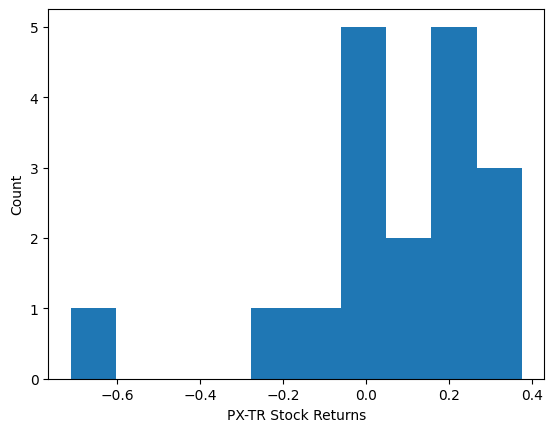

In [213]:
# Histogram
plt.hist(pxtr["Log_return"])
plt.ylabel("Count")
plt.xlabel("PX-TR Stock Returns")
plt.savefig("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/Visualizations/Stocks/PXTR_hist.pdf", format="pdf", bbox_inches="tight")
plt.show

In [214]:
# Check for Outliers
# Calculate mean, std
pxtr_std = np.std(pxtr["Log_return"])
pxtr_mean = np.mean(pxtr["Log_return"])

# Calculate Z-Score
pxtr["Z-Score"] = np.nan
for i in range(len(pxtr)):
    pxtr.loc[i, "Z-Score"] = ((pxtr.loc[i, "Log_return"] - pxtr_mean) / pxtr_std)

# Print out Outliers
pxtr[np.abs(pxtr["Z-Score"])>3] # 2008 is an outlier

,Exchange Date,Close,Net,%Chg,Open,Low,High,Year,Log_return,Z-Score
2,2008-12-31,949.08,-986.73,-0.50972,1928.86,773.84,1928.86,2008,-0.7128,-3.165384


In [215]:
# Drop outliers
pxtr = pxtr[np.abs(pxtr["Z-Score"])<3]

In [216]:
# Display statistics
pxtr_mean = np.mean(pxtr["Log_return"])
pxtr_var = np.var(pxtr["Log_return"])
print(f"Czech stocks have mean {np.round(pxtr_mean, 4)} and variance {np.round(pxtr_var,4)}.")

Czech stocks have mean 0.1016 and variance 0.0257.


In [217]:
# Check for max and min return
pxtr[pxtr["Log_return"] == np.max((pxtr["Log_return"]))], pxtr[pxtr["Log_return"] == np.min(pxtr["Log_return"])]

(   Exchange Date    Close     Net     %Chg    Open      Low     High  Year  \
 15    2021-12-31  2915.25  910.71  0.45432  2006.6  1976.32  2918.25  2021   
 
     Log_return   Z-Score  
 15      0.3745  1.309098  ,
   Exchange Date    Close     Net     %Chg     Open      Low     High  Year  \
 5    2011-12-31  1181.29 -319.55 -0.21291  1523.62  1093.06  1589.37  2011   
 
    Log_return   Z-Score  
 5     -0.2394 -1.217237  )

In [218]:
# Save Mean and Variance
params_to_json("PXTR", np.round(pxtr_mean,4), np.round(pxtr_var,4))

In [219]:
# Export back to Excel
pxtr.to_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/stocks/CZStocks.xlsx", sheet_name="PXTR")

### **EU Stocks: .SX5GT**

In [220]:
# Read data
sx5gt = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/stocks/SX5GT_00_25.xlsx", sheet_name="Data")

In [221]:
# Change Date to Date format, filter for end of 2024 as cut off point
sx5gt['Exchange Date'] = pd.to_datetime(sx5gt['Exchange Date'])
sx5gt = sx5gt[sx5gt['Exchange Date'] <= '2024-12-31']

# Add "Year" column
sx5gt['Year'] = pd.DatetimeIndex(sx5gt['Exchange Date']).year

In [222]:
# Reset index
sx5gt.reset_index(inplace=True)
sx5gt.drop("index", axis=1, inplace=True)

# Data in ascending order by year
sx5gt = sx5gt.sort_values(by="Exchange Date").reset_index().drop("index", axis=1)

In [223]:
# Create year-to-year log return 
sx5gt["Log_return"] = np.nan
for i in range(1,len(sx5gt)):
    sx5gt.loc[i, "Log_return"] = np.round(np.log(sx5gt.loc[i, "Close"]/sx5gt.loc[i-1, "Close"]), 4)

<function matplotlib.pyplot.show(close=None, block=None)>

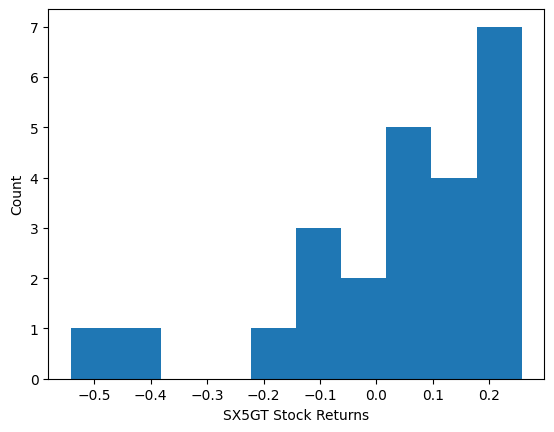

In [224]:
# Histogram
plt.hist(sx5gt["Log_return"])
plt.ylabel("Count")
plt.xlabel("SX5GT Stock Returns")
plt.savefig("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/Visualizations/Stocks/SX5GT_hist.pdf", format="pdf", bbox_inches="tight")
plt.show

In [225]:
# Check for Log Outliers
# Calculate mean, std
sx5gt_std_log = np.std(sx5gt["Log_return"])
sx5gt_mean_log = np.mean(sx5gt["Log_return"])

# Calculate Z-Score
sx5gt["Z-Score"] = np.nan
for i in range(len(sx5gt)):
    sx5gt.loc[i, "Z-Score"] = ((sx5gt.loc[i, "Log_return"] - sx5gt_std_log) / sx5gt_std_log)

# Print out Outliers
sx5gt[np.abs(sx5gt["Z-Score"])>=3] # 2002, 2008

,Exchange Date,Close,Net,%Chg,Open,Low,High,Year,Log_return,Z-Score
2,2002-12-31,521.95,-290.11,-0.357252,801.39,469.48,817.94,2002,-0.4420,-3.172310
8,2008-12-31,653.96,-470.00,-0.418164,1108.72,577.46,1108.72,2008,-0.5416,-3.661817


In [226]:
# Drop outliers
sx5gt = sx5gt[np.abs(sx5gt["Z-Score"])<3]

In [227]:
# Display statistics
sx5gt_mean = np.mean(sx5gt["Log_return"])
sx5gt_var = np.var(sx5gt["Log_return"])
print(f"Eurozone stocks have mean {np.round(sx5gt_mean, 4)} and variance {np.round(sx5gt_var,4)}.")

Eurozone stocks have mean 0.0835 and variance 0.0174.


In [228]:
# Check for max and min return
sx5gt[sx5gt["Log_return"] == np.max((sx5gt["Log_return"]))], sx5gt[sx5gt["Log_return"] == np.min(sx5gt["Log_return"])]

(   Exchange Date    Close     Net      %Chg     Open      Low     High  Year  \
 19    2019-12-31  1547.04  350.57  0.293004  1189.04  1170.69  1567.61  2019   
 
     Log_return   Z-Score  
 19       0.257  0.263085  ,
   Exchange Date   Close     Net     %Chg   Open     Low     High  Year  \
 1    2001-12-31  812.06 -187.94 -0.18794  985.3  613.58  1003.46  2001   
 
    Log_return   Z-Score  
 1     -0.2082 -2.023247  )

In [229]:
# Save Mean and Variance
params_to_json("SX5GT", np.round(sx5gt_mean,4), np.round(sx5gt_var,4))

In [230]:
# Export back to Excel
sx5gt.to_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/stocks/EUStocks.xlsx", sheet_name="SX5GT")

### **US Stocks: .SPXTR**

In [231]:
# Load data
spxtr = pd.read_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/stocks/SPXTR_88_25.xlsx", sheet_name="Data")

In [232]:
# Change Date to Date format, filter for end of 2024 as cut off point
spxtr['Exchange Date'] = pd.to_datetime(spxtr['Exchange Date'])
spxtr = spxtr[spxtr['Exchange Date'] <= '2024-12-31']

# Add "Year" column
spxtr['Year'] = pd.DatetimeIndex(spxtr['Exchange Date']).year

In [233]:
# Reset index
spxtr.reset_index(inplace=True)
spxtr.drop("index", axis=1, inplace=True)

# Data in ascending order by year
spxtr = spxtr.sort_values(by="Exchange Date").reset_index().drop("index", axis=1)

In [234]:
# Create year-to-year log return 
spxtr["Log_return"] = np.nan
for i in range(1,len(spxtr)):
    spxtr.loc[i, "Log_return"] = np.round(np.log(spxtr.loc[i, "Close"]/spxtr.loc[i-1, "Close"]), 4)

<function matplotlib.pyplot.show(close=None, block=None)>

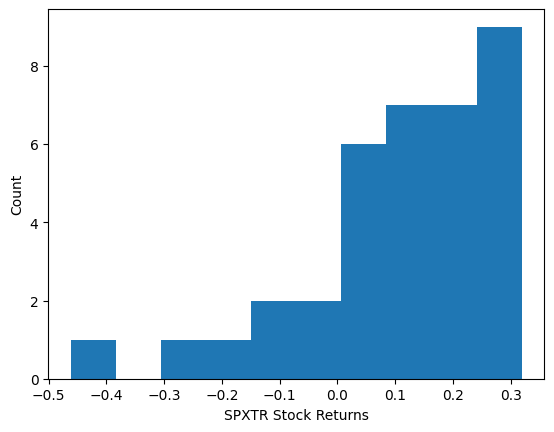

In [235]:
# Histogram
plt.hist(spxtr["Log_return"])
plt.ylabel("Count")
plt.xlabel("SPXTR Stock Returns")
plt.savefig("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/Visualizations/Stocks/SPXTR_hist.pdf", format="pdf", bbox_inches="tight")
plt.show

In [236]:
# Check for Outliers
# Calculate mean, std
spxtr_std = np.std(spxtr["Log_return"])
spxtr_mean = np.mean(spxtr["Log_return"])

# Calculate Z-Score
spxtr["Z-Score"] = np.nan
for i in range(len(spxtr)):
    spxtr.loc[i, "Z-Score"] = ((spxtr.loc[i, "Log_return"] - spxtr_mean) / spxtr_std)

# Print out Outliers
spxtr[np.abs(spxtr["Z-Score"])>3] # 2008

,Exchange Date,Close,Net,%Chg,Open,Low,High,Volume,Year,Log_return,Z-Score
20,2008-12-31,1452.9764,-853.2561,-0.369978,2273.4058,1206.0388,2273.4139,NaN,2008,-0.462,-3.327813


In [237]:
# Drop outliers
spxtr = spxtr[np.abs(spxtr["Z-Score"])<3]

In [238]:
# Display statistics
spxtr_mean = np.mean(spxtr["Log_return"])
spxtr_var = np.var(spxtr["Log_return"])
print(f"US stocks have mean {np.round(spxtr_mean, 4)} and variance {np.round(spxtr_var,4)}.")

US stocks have mean 0.1218 and variance 0.0205.


In [239]:
# Check for max and min return
spxtr[spxtr["Log_return"] == np.max((spxtr["Log_return"]))], spxtr[spxtr["Log_return"] == np.min(spxtr["Log_return"])]

(  Exchange Date     Close      Net      %Chg      Open       Low      High  \
 7    1995-12-31  792.0419  216.337  0.375778  575.5206  575.5206  798.7597   
 
    Volume  Year  Log_return   Z-Score  
 7     NaN  1995       0.319  1.250908  ,
    Exchange Date      Close       Net      %Chg       Open        Low  \
 14    2002-12-31  1261.1763 -357.8025 -0.221005  1628.5061  1108.9094   
 
          High  Volume  Year  Log_return   Z-Score  
 14  1655.4431     NaN  2002     -0.2498 -2.083761  )

In [240]:
# Save Mean and Variance
params_to_json("SPXTR", np.round(spxtr_mean,4), np.round(spxtr_var,4))

In [241]:
# Export back to Excel
spxtr.to_excel("/Users/jachymsvejda/Documents/GitHub/FIRE_Rule_from_a_Perspective_of_a_Czech_Retail_Investor/data/stocks/USStocks.xlsx", sheet_name="SPXTR")